## K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm used for both classification and regression tasks. It is a non-parametric, instance-based learning algorithm that makes predictions based on the similarity between observations.

Unlike algorithms that learn an explicit mathematical model during training, KNN stores the training data and uses distance measurements to identify observations that are most similar to a new data point.

The algorithm works by identifying the K closest observations (neighbors) to a given data point and using their target values to make predictions.

**How KNN works:**

1. **Choose K:** Select the number of nearest neighbors to consider when making predictions.
2. **Calculate distances:** Measure the distance between the new observation and all observations in the training dataset.
3. **Identify nearest neighbors:** Select the K observations with the smallest distances.
4. **Make predictions:** Use the selected neighbors to determine the predicted outcome.

**KNN supports two main types of prediction:**

- **Classification:** Assigns a class to a new observation based on the majority class among its K nearest neighbors.
- **Regression:** Predicts a continuous numerical value by calculating the average target value of its K nearest neighbors.

### Distance Measurement

KNN relies on distance metrics to determine how similar or different observations are. One commonly used metric is Euclidean distance, which calculates the straight-line distance between two data points.

### Choosing the Value of K

The choice of K influences how the algorithm makes predictions:

- A small K makes the model more sensitive to individual observations and noise.
- A large K considers more neighbors, producing smoother predictions but potentially overlooking local patterns.

The optimal value of K can be determined through experimentation and cross-validation.

### Advantages of KNN

- Simple to understand and implement.
- Supports both classification and regression.
- Does not require assumptions about the underlying data distribution.
- Can capture nonlinear relationships in data.

### Limitations of KNN

- Computationally expensive when making predictions on large datasets.
- Sensitive to feature scaling.
- Performance can deteriorate with high-dimensional data.
- Sensitive to irrelevant features and noisy observations.

In [55]:
# imports 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,roc_auc_score)

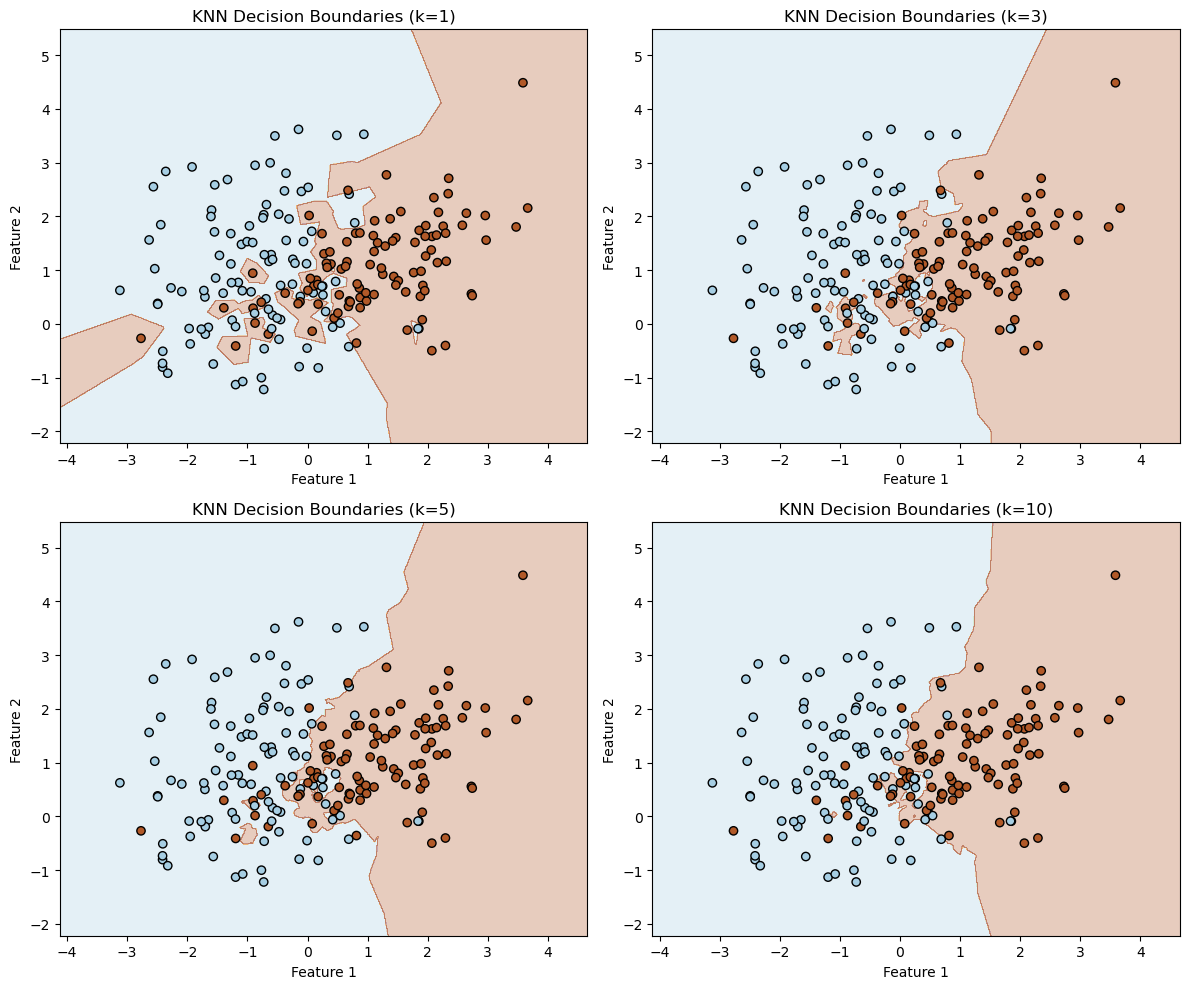

In [5]:

X, y = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0, n_clusters_per_class=1, random_state=42)

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
k_values = [1, 3, 5, 10]

for ax, k in zip(axs.flat, k_values):

    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X, y)
    
    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Paired)
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k',
               cmap=plt.cm.Paired, marker='o')
    ax.set_title(f'KNN Decision Boundaries (k={k})')
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')

plt.tight_layout()
plt.show()

## Regression

In [7]:
# load dataset
# Load the California Housing dataset
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()

# Convert dataset into a DataFrame
house_df = pd.DataFrame(housing.data, columns=housing.feature_names)

# Add target variable
house_df['MedHouseVal'] = housing.target

print(house_df.shape)
house_df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [8]:
house_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [9]:
house_df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [11]:
# missing values
house_df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [13]:
# features and targets
X = house_df.drop('MedHouseVal', axis=1)
y = house_df['MedHouseVal']

In [17]:
# split data
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
y_train.shape

(16512, 8)
(4128, 8)


(16512,)

In [15]:
# feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [18]:
# Initialize the KNN Regression model
knn_reg = KNeighborsRegressor(n_neighbors=5)

# Train the model
knn_reg.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [19]:
# predictions
y_pred = knn_reg.predict(X_test_scaled)

In [20]:
# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R-squared:", r2)

Mean Absolute Error: 0.4461535271317829
Mean Squared Error: 0.4324216146043236
Root Mean Squared Error: 0.6575877238850522
R-squared: 0.6700101862970989


In [21]:
# Actual vs predicted
# Create a comparison DataFrame
knn_results = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': y_pred
})

knn_results.head(10)

,Actual Values,Predicted Values
0,0.47700,0.498800
1,0.45800,0.764600
2,5.00001,4.750006
3,2.18600,2.876600
4,2.78000,2.726200
5,1.58700,1.778600
6,1.98200,2.718200
7,1.57500,1.924600
8,3.40000,2.031400
9,4.46600,4.955608


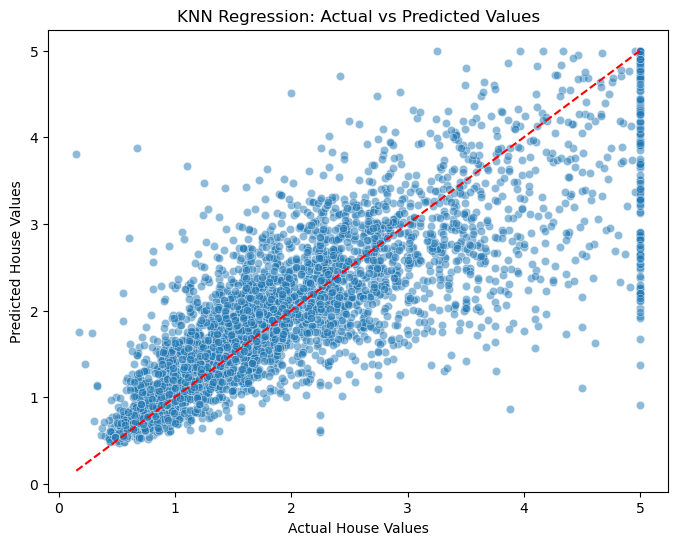

In [22]:
plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test,y=y_pred,alpha=0.5)

plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],color='red',linestyle='--')

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.title('KNN Regression: Actual vs Predicted Values')

plt.show()

In [23]:
# Predictions on training data
y_train_pred = knn_reg.predict(X_train_scaled)

# Calculate R-squared scores
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_pred)

print("Training R²:", train_r2)
print("Testing R²:", test_r2)

Training R²: 0.7968981277117805
Testing R²: 0.6700101862970989


In [24]:
# Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

param_grid = {'n_neighbors': range(1, 31),'weights': ['uniform', 'distance'],'p': [1, 2]}

knn_grid = GridSearchCV(KNeighborsRegressor(),param_grid,cv=5,scoring='neg_mean_squared_error',n_jobs=-1)

knn_grid.fit(X_train_scaled, y_train)

print("Best Parameters:", knn_grid.best_params_)
print("Best CV MSE:", -knn_grid.best_score_)

Best Parameters: {'n_neighbors': 9, 'p': 1, 'weights': 'distance'}
Best CV MSE: 0.3608964017272985


In [25]:
# Retrieve the best model
best_knn = knn_grid.best_estimator_

# Make predictions
y_pred_tuned = best_knn.predict(X_test_scaled)

# Evaluate the tuned model
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_mse = mean_squared_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_pred_tuned)

print("Tuned Model Performance")
print("Mean Absolute Error:", tuned_mae)
print("Mean Squared Error:", tuned_mse)
print("Root Mean Squared Error:", tuned_rmse)
print("R-squared:", tuned_r2)

Tuned Model Performance
Mean Absolute Error: 0.40580195325466495
Mean Squared Error: 0.3641506481894662
Root Mean Squared Error: 0.6034489607162036
R-squared: 0.72210916268423


In [26]:
# Compare model performance
comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2'],
    'Original KNN': [mae, mse, rmse, r2],
    'Tuned KNN': [tuned_mae, tuned_mse, tuned_rmse, tuned_r2]
})

comparison

,Metric,Original KNN,Tuned KNN
0,MAE,0.446154,0.405802
1,MSE,0.432422,0.364151
2,RMSE,0.657588,0.603449
3,R2,0.670010,0.722109


In [27]:
# Compare actual and tuned predictions
knn_tuned_results = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': y_pred_tuned
})

knn_tuned_results.head(10)

,Actual Values,Predicted Values
0,0.47700,0.509973
1,0.45800,0.937236
2,5.00001,4.421740
3,2.18600,2.704233
4,2.78000,2.704506
5,1.58700,2.116799
6,1.98200,2.573868
7,1.57500,1.853843
8,3.40000,2.174151
9,4.46600,4.898019


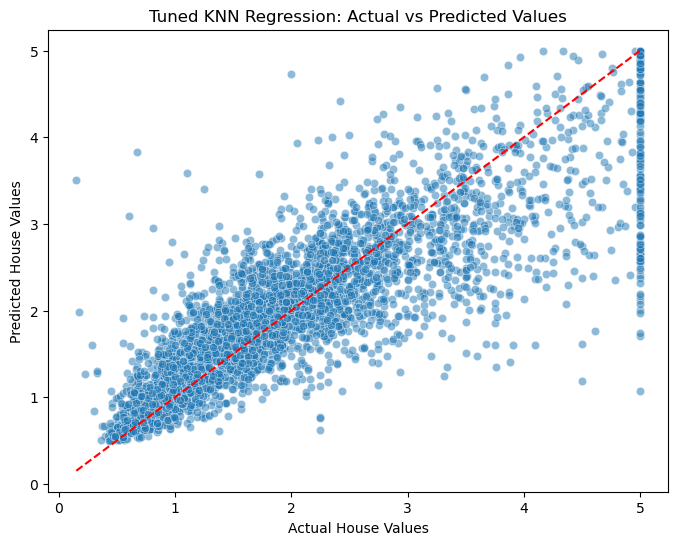

In [28]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_tuned,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.title('Tuned KNN Regression: Actual vs Predicted Values')

plt.show()

In [29]:
y_train_pred_tuned = best_knn.predict(X_train_scaled)

print("Tuned Training R²:", r2_score(y_train, y_train_pred_tuned))
print("Tuned Testing R²:", r2_score(y_test, y_pred_tuned))

Tuned Training R²: 1.0
Tuned Testing R²: 0.72210916268423


#### KNN Regression

The K-Nearest Neighbors Regression model was implemented using the California Housing dataset to predict median house values.

The initial model, configured with five neighbors, achieved an R² score of 0.6700 on the testing dataset.

Hyperparameter tuning using GridSearchCV identified the optimal configuration as nine neighbors, Manhattan distance, and distance-based weighting.

The optimized model achieved an R² score of 0.7221, with an MAE of 0.4058 and RMSE of 0.6034.

The results demonstrate that hyperparameter tuning improved the model's predictive performance by reducing prediction errors and increasing the proportion of variance explained.

Overall, the tuned KNN Regression model performed better than the initial model, although some prediction errors remain.

## Classification

In [31]:
# Load Breast Cancer dataset
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

# Create DataFrame
cancer_df = pd.DataFrame(cancer.data, columns=cancer.feature_names)

# Add target variable
cancer_df['target'] = cancer.target

print(cancer_df.shape)
cancer_df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [32]:
cancer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [33]:
cancer_df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [34]:
# Target distribution
cancer_df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

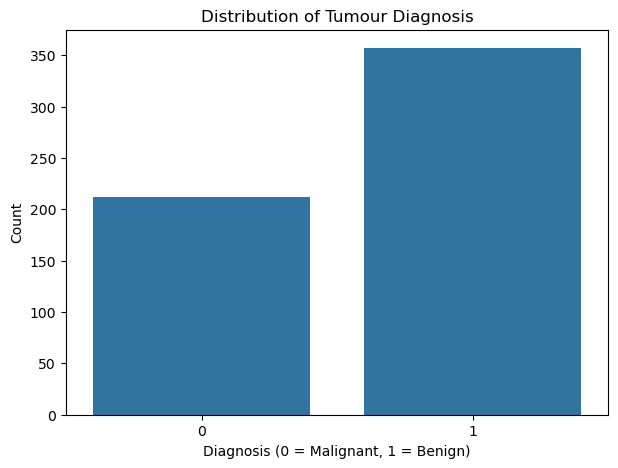

In [36]:
# Visualize target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=cancer_df, x='target')

plt.title('Distribution of Tumour Diagnosis')
plt.xlabel('Diagnosis (0 = Malignant, 1 = Benign)')
plt.ylabel('Count')

plt.show()

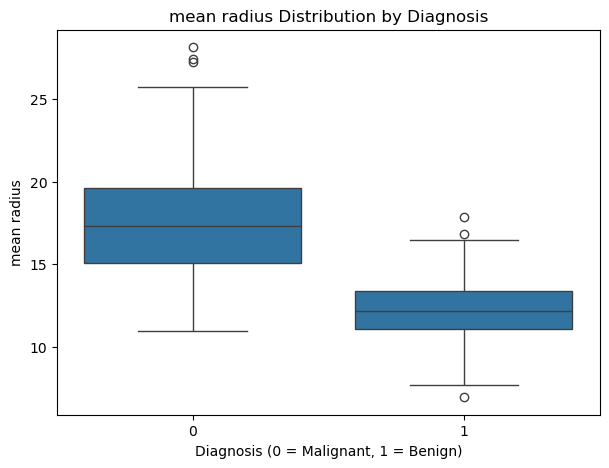

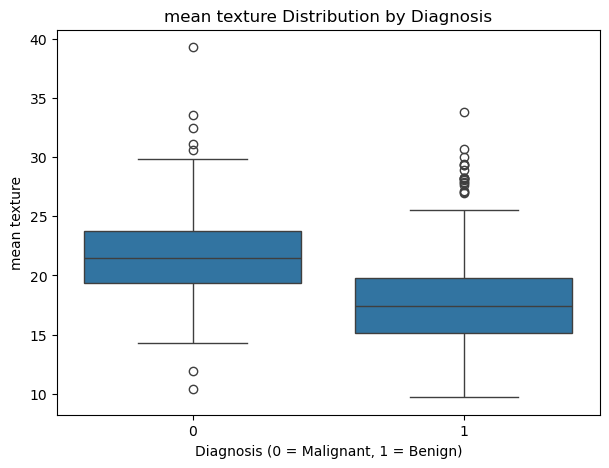

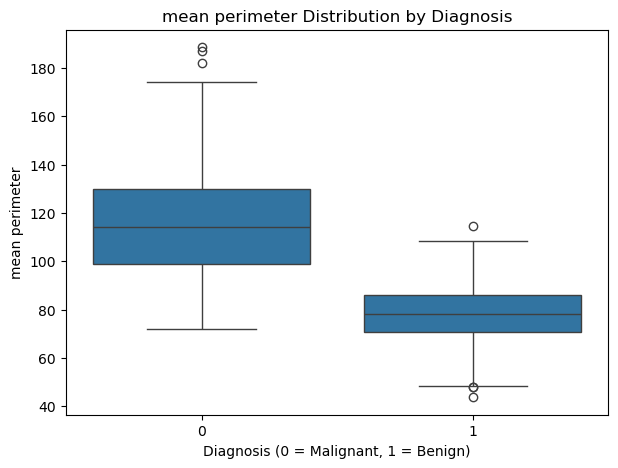

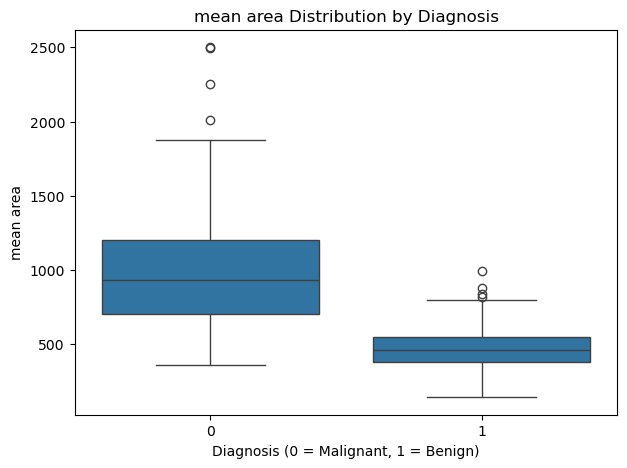

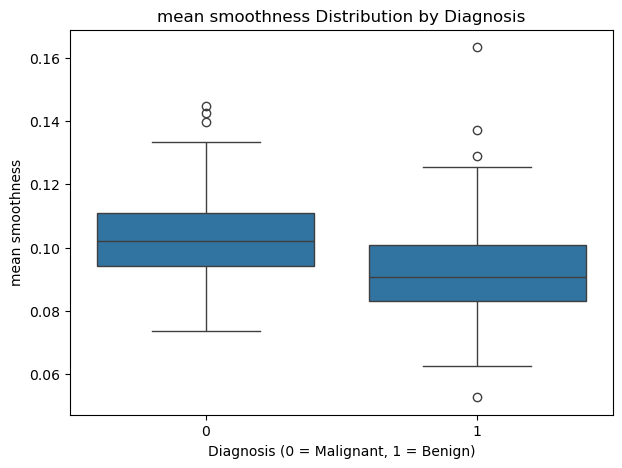

In [38]:
# Feature distribution
selected_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area',
    'mean smoothness'
]

for feature in selected_features:
    plt.figure(figsize=(7, 5))

    sns.boxplot(data=cancer_df,x='target',y=feature)

    plt.title(f'{feature} Distribution by Diagnosis')
    plt.xlabel('Diagnosis (0 = Malignant, 1 = Benign)')
    plt.show()

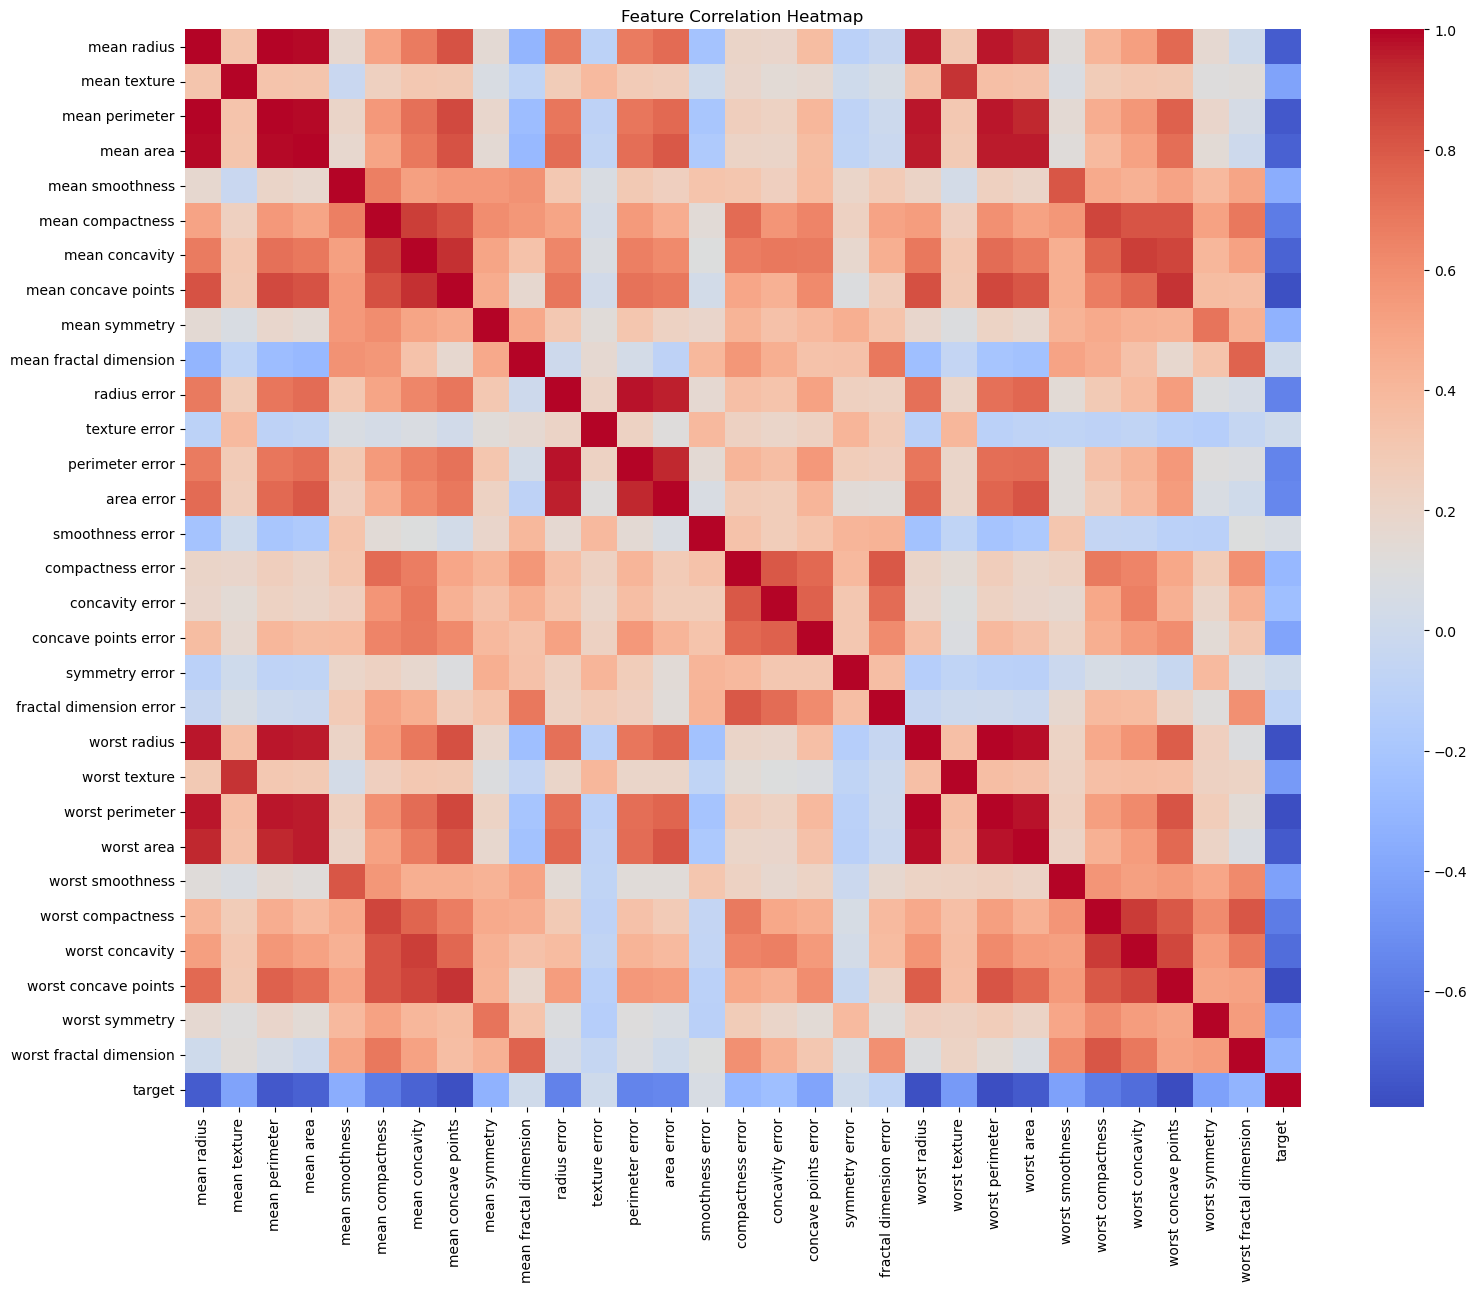

In [40]:
# feature correlation
plt.figure(figsize=(18, 14))

sns.heatmap(cancer_df.corr(),cmap='coolwarm',annot=False)

plt.title('Feature Correlation Heatmap')

plt.show()

In [42]:
# Separate features and target variable
X = cancer_df.drop('target', axis=1)
y = cancer_df['target']

In [43]:
# split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

In [44]:
#  feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [45]:
# Modelling
# Initialize KNN Classifier
knn_clf = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_clf.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [46]:
# predictions
y_test_pred = knn_clf.predict(X_test_scaled)

In [47]:
# accuracy
accuracy = accuracy_score(y_test, y_test_pred)

print("Accuracy:", accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test,y_test_pred,target_names=cancer.target_names))

# ROC-AUC
y_test_proba = knn_clf.predict_proba(X_test_scaled)[:, 1]

roc_auc = roc_auc_score(y_test, y_test_proba)

print("ROC-AUC:", roc_auc)

Accuracy: 0.956140350877193

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

ROC-AUC: 0.9788359788359788


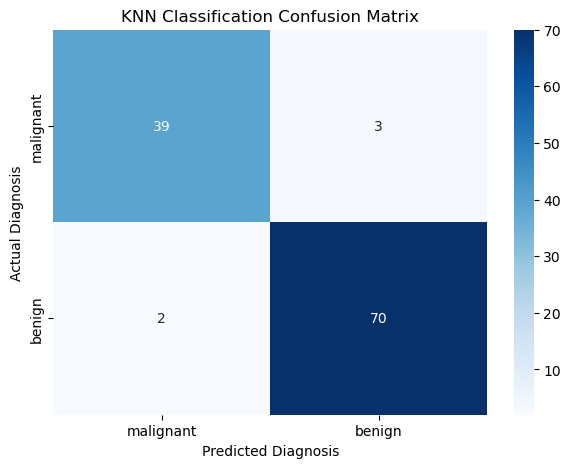

In [48]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=cancer.target_names,yticklabels=cancer.target_names)

plt.xlabel('Predicted Diagnosis')
plt.ylabel('Actual Diagnosis')
plt.title('KNN Classification Confusion Matrix')

plt.show()

In [49]:
# Actual vs predicted
knn_clf_results = pd.DataFrame({
    'Actual Category': y_test.values,
    'Predicted Category': y_test_pred
})

knn_clf_results.head(10)

,Actual Category,Predicted Category
0,0,0
1,1,1
2,0,0
3,1,0
4,0,0
5,1,1
6,1,1
7,0,0
8,0,0
9,0,0


In [50]:
# Hyperparameter Tuning
from sklearn.pipeline import Pipeline

# Create pipeline
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# Define hyperparameter grid
param_grid = {
    'knn__n_neighbors': range(1, 31),
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

# Initialize GridSearchCV
knn_grid = GridSearchCV(knn_pipeline,param_grid,cv=5,scoring='roc_auc',n_jobs=-1)

# Train and tune the model
knn_grid.fit(X_train, y_train)

print("Best Parameters:", knn_grid.best_params_)
print("Best CV ROC-AUC:", knn_grid.best_score_)

Best Parameters: {'knn__n_neighbors': 9, 'knn__p': 2, 'knn__weights': 'distance'}
Best CV ROC-AUC: 0.9930340557275542


In [51]:
# Retrieve the best model
best_knn_clf = knn_grid.best_estimator_

# predictions
y_pred_tuned = best_knn_clf.predict(X_test)

# Predict probabilities
y_proba_tuned = best_knn_clf.predict_proba(X_test)[:, 1]

In [52]:
# Tuned evaluation
# Accuracy
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

# Classification report
print("Tuned Model Classification Report:")
print(classification_report(y_test,y_pred_tuned,target_names=cancer.target_names))

# ROC-AUC
tuned_roc_auc = roc_auc_score(y_test, y_proba_tuned)

print("Tuned Accuracy:", tuned_accuracy)
print("Tuned ROC-AUC:", tuned_roc_auc)

Tuned Model Classification Report:
              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Tuned Accuracy: 0.9736842105263158
Tuned ROC-AUC: 0.9933862433862434


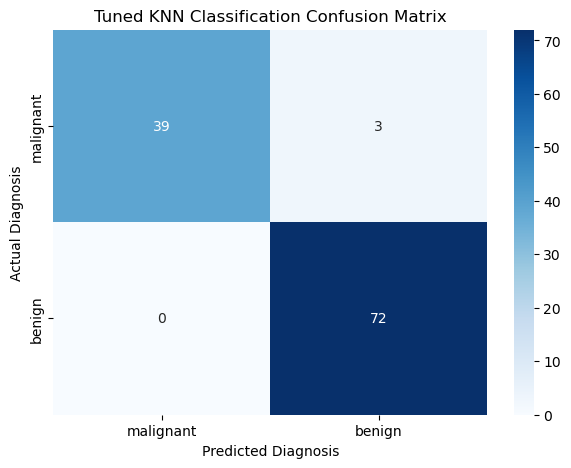

In [53]:
# tuned confusion matrix
# Generate confusion matrix
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(7, 5))

sns.heatmap(cm_tuned,annot=True,fmt='d',cmap='Blues',xticklabels=cancer.target_names,yticklabels=cancer.target_names)

plt.xlabel('Predicted Diagnosis')
plt.ylabel('Actual Diagnosis')
plt.title('Tuned KNN Classification Confusion Matrix')

plt.show()

In [56]:
# Original model metrics
original_precision = precision_score(y_test, y_test_pred)
original_recall = recall_score(y_test, y_test_pred)
original_f1 = f1_score(y_test, y_test_pred)

# Tuned model metrics
tuned_precision = precision_score(y_test, y_pred_tuned)
tuned_recall = recall_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)

# Comparison
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Original KNN': [
        accuracy, original_precision, original_recall,
        original_f1, roc_auc
    ],
    'Tuned KNN': [
        tuned_accuracy, tuned_precision, tuned_recall,
        tuned_f1, tuned_roc_auc
    ]
})

comparison

,Metric,Original KNN,Tuned KNN
0,Accuracy,0.956140,0.973684
1,Precision,0.958904,0.960000
2,Recall,0.972222,1.000000
3,F1-Score,0.965517,0.979592
4,ROC-AUC,0.978836,0.993386


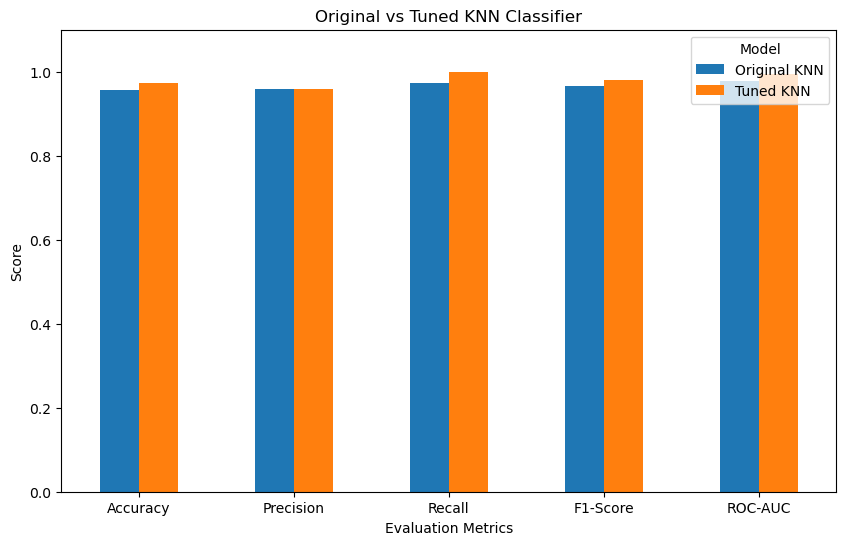

In [57]:
comparison.set_index('Metric').plot(kind='bar',figsize=(10, 6))

plt.title('Original vs Tuned KNN Classifier')
plt.ylabel('Score')
plt.xlabel('Evaluation Metrics')
plt.xticks(rotation=0)
plt.legend(title='Model')
plt.ylim(0, 1.1)
plt.show()

### Classification

The K-Nearest Neighbors Classification algorithm was implemented using the Breast Cancer Wisconsin dataset to classify tumours as malignant or benign.

The initial model, configured with five neighbors, achieved an accuracy of 95.61% and a ROC-AUC score of 0.9788.

Hyperparameter tuning using GridSearchCV identified the optimal configuration as nine neighbors, Euclidean distance, and distance-based weighting.

The optimized model achieved an accuracy of 97.37%, an F1-score of 0.9796, and a ROC-AUC score of 0.9934.

The comparison demonstrated improvements in overall classification performance following hyperparameter optimization.

Overall, the tuned KNN Classifier performed better than the initial model on the testing dataset, demonstrating the importance of hyperparameter selection in improving model performance.

However, these results are based on a single train-test split and should not be interpreted as evidence of clinical readiness.